# FTEC next-day direction from price and news-sentiment history

**Question:** Does adding the history of broad financial-news sentiment improve prediction of
whether FTEC's next trading-day close is higher than its current close?

This revised midterm notebook uses the longer, already-scored news archive, keeps all its
companies and topics, and runs class-related baselines: regularized logistic regression and
random forests, followed by Prophet and ordinary/Ridge/Lasso return regression. The earlier short pilot is superseded
by this experiment; these are exploratory results, not a claim of profitable trading.

Run all cells from the extracted project folder. Dependencies are in `requirements.txt`.
The notebook also downloads the two source files if the local snapshots are absent.


In [1]:
from pathlib import Path
import json
import hashlib
import urllib.request
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, log_loss

ROOT = Path.cwd()
if (ROOT / 'ftec_midterm' / 'data').exists():
    ROOT = ROOT / 'ftec_midterm'
RAW = ROOT / 'data' / 'raw'
OUT = ROOT / 'results' / 'direction'
PROCESSED = ROOT / 'data' / 'processed'
for folder in [RAW, OUT, PROCESSED]:
    folder.mkdir(parents=True, exist_ok=True)
SOURCES = {
    'ftec_2016_2023_nasdaq.json': 'https://api.nasdaq.com/api/quote/FTEC/historical?assetclass=etf&limit=5000&fromdate=2013-10-24&todate=2023-12-29',
    'nasdaq_news_scores.parquet': 'https://huggingface.co/datasets/HYL/NASDAQ-News-Multi-LLM-Scores/resolve/main/scores.parquet'
}
for filename, url in SOURCES.items():
    path = RAW / filename
    if not path.exists():
        request = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(request, timeout=90) as response:
            path.write_bytes(response.read())
print('Python', platform.python_version(), '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)


Python 3.12.14 | pandas 2.2.3 | scikit-learn 1.8.0


## Sources and what is in the data

**FTEC prices:** [Nasdaq FTEC historical data](https://www.nasdaq.com/market-activity/etf/ftec/historical),
downloaded through the API linked in the first code cell. The request asked for 2013–2023,
but the actual returned history starts November 14, 2016 and ends December 29, 2023:
**1,793 daily open/high/low/close/volume records**. We use the returned dates, not the requested
start date. These are price returns, without a separate dividend adjustment.

**Already-scored news:** [HYL/NASDAQ-News-Multi-LLM-Scores](https://huggingface.co/datasets/HYL/NASDAQ-News-Multi-LLM-Scores),
specifically the downloadable `scores.parquet` file. The actual file contains **127,176
dated article/ticker records for 89 symbols**, dated 2009–early 2024. It includes the
title, date, ticker association, publisher/URL fields, and multiple model-generated sentiment
and risk scores. It is derived from [FNSPID](https://huggingface.co/datasets/Zihan1004/FNSPID)
and FinRL_DeepSeek. Cite Dong, Fan, and Peng (2024),
[*FNSPID: A Comprehensive Financial News Dataset in Time Series*](https://arxiv.org/abs/2402.06698),
as well as HYL's scored release. The scored release lists CC BY-NC 4.0; its original README
is included. Scores are model estimates, not human ground truth.

We choose the complete **`sentiment_nano_title`** column before evaluating forecasts,
map its 1–5 scale to −1–1, and keep all companies and topics. This is a broad company-news
proxy, **not direct FTEC sentiment** and not a complete or representative census of market news.
No comparison of the many alternative score columns is made on the test set.

Snapshots downloaded during the November 13, 2026 session (America/Los_Angeles).
`data_manifest.json` preserves URLs and hashes. The runtime download fallback may retrieve
a newer source version; use the bundled snapshots to reproduce this run exactly.


In [2]:
raw_prices = json.loads((RAW / 'ftec_2016_2023_nasdaq.json').read_text())
prices = pd.DataFrame(raw_prices['data']['tradesTable']['rows'])
prices['date'] = pd.to_datetime(prices['date'], format='%m/%d/%Y')
for column in ['open', 'high', 'low', 'close', 'volume']:
    prices[column] = pd.to_numeric(prices[column].str.replace(',', '', regex=False).str.replace('$', '', regex=False), errors='coerce')
prices = prices.sort_values('date').reset_index(drop=True)
assert prices.date.is_unique
assert len(prices) == int(raw_prices['data']['totalRecords'])
assert prices[['open', 'high', 'low', 'close', 'volume']].notna().all().all()
assert (prices.close > 0).all()

news_raw = pd.read_parquet(RAW / 'nasdaq_news_scores.parquet')
assert news_raw['sentiment_nano_title'].notna().all()
assert news_raw['sentiment_nano_title'].between(1, 5).all()
news = news_raw[['Date', 'Article_title', 'Stock_symbol', 'sentiment_nano_title']].copy()
news['news_date'] = pd.to_datetime(news['Date'].str.replace(' UTC', '', regex=False)).dt.normalize()
news['sentiment'] = (news['sentiment_nano_title'].astype(float) - 3) / 2
news['title_key'] = news['Article_title'].str.lower().str.replace(r'[^a-z0-9]+', '', regex=True)
articles = news.groupby(['news_date', 'title_key'], as_index=False).agg(sentiment=('sentiment', 'mean'), ticker_tags=('Stock_symbol', 'nunique'))

print('FTEC:', len(prices), 'sessions,', prices.date.min().date(), 'through', prices.date.max().date())
print('News:', len(news_raw), 'article/ticker rows;', news_raw.Stock_symbol.nunique(), 'symbols')
print('News dates:', news.news_date.min().date(), 'through', news.news_date.max().date())
print('Unique date + normalized-title groups:', len(articles))
prices.to_csv(PROCESSED / 'ftec_long_prices.csv', index=False)


FTEC: 1793 sessions, 2016-11-14 through 2023-12-29
News: 127176 article/ticker rows; 89 symbols
News dates: 2009-07-07 through 2024-01-09
Unique date + normalized-title groups: 117277


## Align news conservatively and construct histories

Older timestamps are often date-only. We discard all intraday precision and assign an
article dated D to the **first downloaded trading session strictly after D**. The model
makes its prediction after that session's close, for the next session's close.
This avoids treating a midnight placeholder as evidence that an article was available
before the same day's close. It does not independently verify whether dates are original
publication dates rather than updates. The scoring models were applied retrospectively;
their outputs are not proven point-in-time information. This is not a verified live backtest.

Repeated date/title groups are counted once, averaging the selected score across any ticker
tags. This removes exact headline duplicates, not all syndicated paraphrases.
We retain every topic and ticker present in the source. Weekends and holidays map to the
next available session. Articles after the price history ends are excluded.

Daily sentiment is the mean of available article scores; no-article sessions are represented
by a zero placeholder **and an article-count feature**, so missing coverage can be distinguished
from a neutral score. Differences may still reflect changes in coverage rather than investor mood.

Price features: the five most recent daily returns, five-day momentum, trailing five-day volatility,
and close relative to its trailing five-day price average.
Sentiment features: the five most recent daily scores, a trailing five-day mean, first difference
("velocity"), second difference ("acceleration"), and log(1 + article count).
Only trailing observations enter a feature row.


In [3]:
session_dates = prices['date'].to_numpy(dtype='datetime64[ns]')
positions = np.searchsorted(session_dates, articles.news_date.to_numpy(dtype='datetime64[ns]'), side='right')
usable = positions < len(prices)
articles = articles.loc[usable].copy()
positions = positions[usable]
articles['available_date'] = session_dates[positions]
assert (articles.available_date > articles.news_date).all()
daily = articles.groupby('available_date')['sentiment'].agg(['mean', 'count'])
daily.columns = ['sentiment', 'article_count']
frame = prices.merge(daily, left_on='date', right_index=True, how='left')
frame[['sentiment', 'article_count']] = frame[['sentiment', 'article_count']].fillna(0)
frame['return'] = frame.close.pct_change()
frame['target_return'] = frame['return'].shift(-1)
frame['target_date'] = frame.date.shift(-1)
frame['target_up'] = (frame.target_return > 0).astype(int)
price_features = []
sentiment_features = []
for lag in range(5):
    price_name = 'return_lag_' + str(lag)
    sentiment_name = 'sentiment_lag_' + str(lag)
    frame[price_name] = frame['return'].shift(lag)
    frame[sentiment_name] = frame['sentiment'].shift(lag)
    price_features.append(price_name)
    sentiment_features.append(sentiment_name)
frame['momentum_5'] = frame.close.pct_change(5)
frame['volatility_5'] = frame['return'].rolling(5).std()
frame['price_to_mean_5'] = frame.close / frame.close.rolling(5).mean() - 1
frame['sentiment_mean_5'] = frame.sentiment.rolling(5).mean()
frame['sentiment_change'] = frame.sentiment.diff()
frame['sentiment_acceleration'] = frame.sentiment_change.diff()
frame['log_article_count'] = np.log1p(frame.article_count)
price_features += ['momentum_5', 'volatility_5', 'price_to_mean_5']
sentiment_features += ['sentiment_mean_5', 'sentiment_change', 'sentiment_acceleration', 'log_article_count']
all_features = price_features + sentiment_features
frame = frame.dropna(subset=all_features + ['target_return', 'target_date']).copy()
assert (frame.target_date > frame.date).all()
frame.to_csv(PROCESSED / 'direction_features.csv', index=False)
daily.to_csv(PROCESSED / 'daily_broad_sentiment.csv')

print('Usable prediction examples:', len(frame))
print('Prediction dates:', frame.date.min().date(), 'through', frame.date.max().date())
print('Sessions with news:', int((frame.article_count > 0).sum()), '/', len(frame))
print('Dated-title groups used in these examples:', int(frame.article_count.sum()))
print('Features:', len(price_features), 'price;', len(sentiment_features), 'sentiment')


Usable prediction examples: 1787
Prediction dates: 2016-11-21 through 2023-12-28
Sessions with news: 1787 / 1787
Dated-title groups used in these examples: 80129
Features: 8 price; 9 sentiment


## Chronological training, validation, and test sets

- Training: available prediction dates through 2020.
- Validation: 2021, used to select settings.
- Test: 2022–2023, used only after settings are selected.

Remove a boundary training/validation row if its target reaches the next set's first prediction
date. Historical feature windows may cross a boundary because earlier inputs are known at
prediction time; future labels never cross back into training. Standardization is fitted only
on each training set. Up means a strictly higher close; down includes an unchanged close.

Three preselected input sets—price history, sentiment history, and both—are evaluated for
each model. Logistic regression uses L2 regularization and C in {0.01, 0.1, 1, 10}.
Random forests use 100 trees, minimum leaf size 10, sqrt features per split, and depth 2 or 4.
Choose settings by lowest **validation log loss**, then refit on training plus validation.
Report all six model/input combinations, rather than retaining only the best-looking test result.
The baseline always predicts the training-majority class and uses the training up-frequency
as its probability. Accuracy alone can be misleading when up days are more common, so
also report balanced accuracy and log loss. No threshold tuning or repeated search is done.


In [4]:
validation = frame[frame.date.dt.year == 2021].copy()
test = frame[frame.date.dt.year >= 2022].copy()
train = frame[(frame.date.dt.year <= 2020) & (frame.target_date < validation.date.min())].copy()
validation = validation[validation.target_date < test.date.min()].copy()
train_valid = pd.concat([train, validation]).sort_values('date')
assert train.target_date.max() < validation.date.min()
assert train_valid.target_date.max() < test.date.min()
splits = []
for name, subset in [('train', train), ('validation', validation), ('test', test)]:
    assert subset.target_up.nunique() == 2
    splits.append(dict(split=name, examples=len(subset), first_date=str(subset.date.min().date()), last_date=str(subset.date.max().date()), up_fraction=float(subset.target_up.mean())))
split_table = pd.DataFrame(splits)
print(split_table.round(4).to_string(index=False))
split_table.to_csv(OUT / 'splits.csv', index=False)

correlation_rows = []
for feature in ['sentiment_lag_0', 'sentiment_mean_5', 'sentiment_change', 'sentiment_acceleration']:
    correlation_rows.append(dict(feature=feature, train_pearson_with_next_return=float(train[feature].corr(train.target_return))))
correlations = pd.DataFrame(correlation_rows)
correlations.to_csv(OUT / 'training_correlations.csv', index=False)
print()
print('Descriptive training-set correlations, not evidence of forecasting or causality:')
print(correlations.round(5).to_string(index=False))


     split  examples first_date  last_date  up_fraction
     train      1034 2016-11-21 2020-12-30       0.5948
validation       251 2021-01-04 2021-12-30       0.5299
      test       500 2022-01-03 2023-12-28       0.5200

Descriptive training-set correlations, not evidence of forecasting or causality:
               feature  train_pearson_with_next_return
       sentiment_lag_0                         0.04831
      sentiment_mean_5                        -0.02693
      sentiment_change                         0.09893
sentiment_acceleration                         0.09637


In [5]:
feature_sets = {'Price history': price_features, 'Sentiment history': sentiment_features, 'Both': all_features}

def make_model(family, setting):
    if family == 'Logistic regression':
        return make_pipeline(StandardScaler(), LogisticRegression(C=float(setting), max_iter=3000, random_state=42))
    return RandomForestClassifier(n_estimators=100, max_depth=int(setting), min_samples_leaf=10, max_features='sqrt', random_state=42, n_jobs=2)

grids = {'Logistic regression': [0.01, 0.1, 1.0, 10.0], 'Random forest': [2, 4]}
choices = []
validation_rows = []
for family, settings in grids.items():
    for input_name, columns in feature_sets.items():
        candidates = []
        for setting in settings:
            model = make_model(family, setting)
            model.fit(train[columns], train.target_up)
            probability = model.predict_proba(validation[columns])[:, 1]
            loss = log_loss(validation.target_up, probability, labels=[0, 1])
            candidates.append((loss, setting))
            validation_rows.append(dict(model=family, inputs=input_name, setting=setting, validation_log_loss=float(loss)))
        loss, setting = min(candidates, key=lambda item: item[0])
        choices.append((family, input_name, setting))

def evaluate(name, inputs, probabilities, setting=''):
    predicted = (np.asarray(probabilities) >= 0.5).astype(int)
    return dict(model=name, inputs=inputs, setting=str(setting), test_examples=len(test),
                accuracy=float(accuracy_score(test.target_up, predicted)),
                balanced_accuracy=float(balanced_accuracy_score(test.target_up, predicted)),
                log_loss=float(log_loss(test.target_up, probabilities, labels=[0, 1])))

baseline_probability = float(train_valid.target_up.mean())
test_rows = [evaluate('Training frequency baseline', 'No features', np.full(len(test), baseline_probability))]
predictions = test[['date', 'target_date', 'target_return', 'target_up']].reset_index(drop=True).copy()
predictions['baseline_up_probability'] = baseline_probability
fitted_models = {}
for family, input_name, setting in choices:
    columns = feature_sets[input_name]
    model = make_model(family, setting)
    model.fit(train_valid[columns], train_valid.target_up)
    probability = model.predict_proba(test[columns])[:, 1]
    test_rows.append(evaluate(family, input_name, probability, setting))
    predictions[family + ' | ' + input_name] = probability
    fitted_models[(family, input_name)] = model
results = pd.DataFrame(test_rows)
pd.DataFrame(validation_rows).to_csv(OUT / 'validation_grid.csv', index=False)
results.to_csv(OUT / 'test_results.csv', index=False)
predictions.to_csv(OUT / 'test_predictions.csv', index=False)
print(results.round(5).to_string(index=False))
print()
print('Test up-days:', int(test.target_up.sum()), '/', len(test))


                      model            inputs setting  test_examples  accuracy  balanced_accuracy  log_loss
Training frequency baseline       No features                    500     0.520            0.50000   0.70019
        Logistic regression     Price history    0.01            500     0.526            0.50865   0.70760
        Logistic regression Sentiment history    10.0            500     0.508            0.48894   0.71087
        Logistic regression              Both    0.01            500     0.520            0.50288   0.71174
              Random forest     Price history       2            500     0.514            0.49840   0.69920
              Random forest Sentiment history       2            500     0.514            0.49631   0.70729
              Random forest              Both       2            500     0.528            0.50962   0.70283

Test up-days: 260 / 500


## Results and limits

The bars show the same test dates for every model. The dashed line is the training-frequency
baseline's test accuracy. Balanced accuracy averages performance on the up and down classes;
0.5 is its constant-class baseline. Log loss evaluates probabilities, so an accuracy gain with
worse log loss is not an unqualified improvement.

We do not stop only when a correlation appears. All preselected feature/model results are
retained, including weak results. This is a single historical split; daily observations are
dependent, and the sample does not establish performance in other market periods. No
significance, causality, real-time deployability, or profitability claim is made. Input scores
were generated retrospectively by pretrained language models; their historical availability
and freedom from model-training overlap have not been established.

Later work can investigate technology-specific filtering, a second dataset, expanding-window
evaluation, and further Prophet tuning. Other sources were inspected but are not pooled blindly: the Telegram
archive mainly covers a different year; HYL and FNSPID derivatives overlap in original articles;
direct FTEC social pages have access or sparsity limitations. The current experiment retains
all topics in the selected HYL source, as requested.


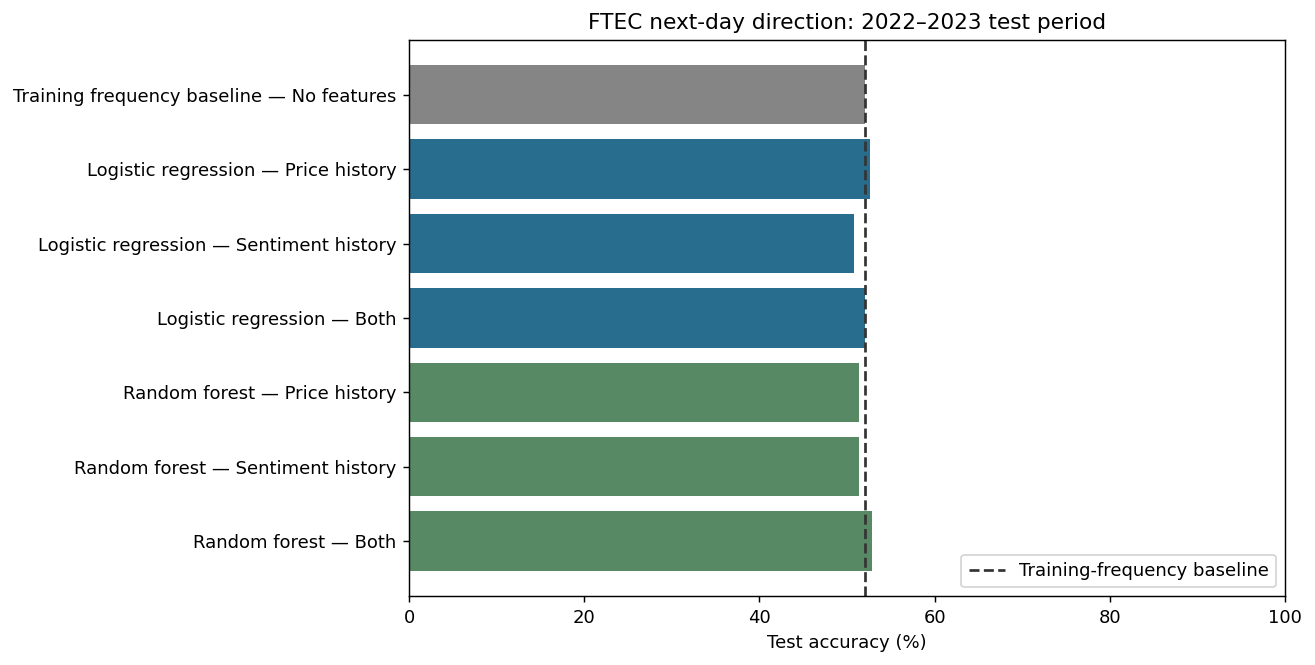

In [6]:
labels = results['model'] + ' — ' + results['inputs']
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
ax.barh(labels, results.accuracy * 100, color=['#858585'] + ['#286c8e'] * 3 + ['#578a64'] * 3)
ax.axvline(results.iloc[0].accuracy * 100, color='#333333', linestyle='--', label='Training-frequency baseline')
ax.set_xlim(0, 100)
ax.set_xlabel('Test accuracy (%)')
ax.set_title('FTEC next-day direction: 2022–2023 test period')
ax.invert_yaxis()
ax.legend(loc='lower right')
fig.savefig(OUT / 'direction_accuracy.png', dpi=160)
plt.show()

summary = {'raw_price_rows': len(prices), 'raw_news_rows': len(news_raw), 'unique_dated_titles': int(news[['news_date', 'title_key']].drop_duplicates().shape[0]),
           'usable_examples': len(frame), 'covered_sessions': int((frame.article_count > 0).sum()),
           'splits': split_table.to_dict(orient='records'), 'test_results': results.to_dict(orient='records'),
           'training_correlations': correlations.to_dict(orient='records')}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2))
manifest = []
for filename, url in SOURCES.items():
    path = RAW / filename
    manifest.append(dict(file='data/raw/' + filename, source_url=url, sha256=hashlib.sha256(path.read_bytes()).hexdigest(), size_bytes=path.stat().st_size))
(ROOT / 'data_manifest.json').write_text(json.dumps(manifest, indent=2))


## Prophet, ordinary regression, Ridge, and Lasso: report-aligned comparison

The current team draft discusses Prophet's component regularization and comparison with
ordinary linear regression, Ridge, and Lasso on next-day returns. We implement that
comparison here, retaining the classification experiments above as initial baselines.
All models use the exact same chronological rows and test dates.

Prophet is an additive forecasting model with trend, seasonal components, and optional
linear extra regressors; it is not ordinary linear regression. See
[Prophet quick start](https://meta.github.io/prophet/docs/quick_start.html) and
[additional regressors](https://meta.github.io/prophet/docs/seasonality,_holiday_effects,_and_regressors.html).

**Target:** next-day return in percentage points. For Prophet, `ds` is the target trading
date and `y` is the return ending on that date. An extra-regressor row contains only price
and sentiment histories from the previous prediction date; it never contains the target
day's actual sentiment or return. Although forecasts for the test dates are computed in
one batch, each conditional feature vector uses only information dated before its target.
Models are fitted once through 2021, without refitting on test labels. This is not an
unconditional two-year forecast made in 2021: later feature vectors become available sequentially.

Three Prophet variants use identical fixed settings: a linear trend, 10 changepoints,
changepoint prior scale 0.05, yearly Fourier order 5, weekly seasonality, no daily seasonality,
and seasonality prior scale 1. Extra regressors are standardized using fitted history with
prior scale 0.1. We compare calendar-only Prophet, Prophet plus price history, and Prophet
plus price and sentiment history. No test-driven parameter search is performed.

For ordinary/Ridge/Lasso regression we use the shared price-plus-sentiment feature set.
Ridge and Lasso penalties are chosen by validation RMSE, then refitted through 2021.
Lasso can zero coefficients; Prophet's component priors do not implement the same L1 selection.
This compares model behavior, not an isolated causal effect of a particular penalty.

Report RMSE, MAE, R² and sign accuracy. The no-change forecast has zero return; for sign
accuracy only, zero is mapped to not-up. A training-mean-return baseline predicts up here.
Prophet point forecasts are not class probabilities, so we do not invent a log-loss score.
This is a follow-up after inspecting earlier results on the same historical period and
remains exploratory; a final confirmation should use a separate period or planned evaluation.


In [7]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def regression_score(name, prediction_pp):
    actual_pp = test.target_return.to_numpy() * 100
    return dict(model=name, test_examples=len(test),
                rmse_pp=float(np.sqrt(mean_squared_error(actual_pp, prediction_pp))),
                mae_pp=float(mean_absolute_error(actual_pp, prediction_pp)),
                r2=float(r2_score(actual_pp, prediction_pp)),
                direction_accuracy=float(accuracy_score(test.target_up, np.asarray(prediction_pp) > 0)))

regression_predictions = test[['date', 'target_date', 'target_return', 'target_up']].reset_index(drop=True).copy()
regression_rows = []
for name, values in [('No change', np.zeros(len(test))), ('Training mean return', np.full(len(test), train_valid.target_return.mean() * 100))]:
    regression_rows.append(regression_score(name, values))
    regression_predictions[name] = values

regression_grids = {'Ridge': [0.1, 1.0, 10.0, 100.0], 'Lasso': [0.001, 0.01, 0.1, 1.0]}
regression_constructors = {'Ridge': Ridge, 'Lasso': Lasso}
regression_settings = {}
regression_validation = []
for name, grid in regression_grids.items():
    candidates = []
    for alpha in grid:
        model = make_pipeline(StandardScaler(), regression_constructors[name](alpha=alpha, max_iter=100000))
        model.fit(train[all_features], train.target_return * 100)
        prediction = model.predict(validation[all_features])
        rmse = float(np.sqrt(mean_squared_error(validation.target_return * 100, prediction)))
        candidates.append((rmse, alpha))
        regression_validation.append(dict(model=name, alpha=alpha, validation_rmse_pp=rmse))
    regression_settings[name] = min(candidates, key=lambda value: value[0])[1]

regression_models = {'Ordinary linear regression': make_pipeline(StandardScaler(), LinearRegression())}
for name, alpha in regression_settings.items():
    regression_models[name] = make_pipeline(StandardScaler(), regression_constructors[name](alpha=alpha, max_iter=100000))
for name, model in regression_models.items():
    model.fit(train_valid[all_features], train_valid.target_return * 100)
    prediction = model.predict(test[all_features])
    regression_predictions[name] = prediction
    regression_rows.append(regression_score(name, prediction))
pd.DataFrame(regression_validation).to_csv(OUT / 'regression_validation.csv', index=False)
lasso_coefficients = regression_models['Lasso'][-1].coef_
pd.DataFrame({'feature': all_features, 'scaled_coefficient_pp': lasso_coefficients}).to_csv(OUT / 'lasso_coefficients.csv', index=False)
print('Selected return-regression penalties:', regression_settings)
print('Lasso nonzero feature coefficients:', int(np.count_nonzero(lasso_coefficients)), '/', len(all_features))
print(pd.DataFrame(regression_rows).round(5).to_string(index=False))


Selected return-regression penalties: {'Ridge': 0.1, 'Lasso': 0.1}
Lasso nonzero feature coefficients: 3 / 17
                     model  test_examples  rmse_pp  mae_pp       r2  direction_accuracy
                 No change            500  1.72537 1.33018 -0.00021               0.480
      Training mean return            500  1.72749 1.32974 -0.00268               0.520
Ordinary linear regression            500  1.78623 1.39325 -0.07202               0.496
                     Ridge            500  1.78439 1.39117 -0.06981               0.488
                     Lasso            500  1.75510 1.36204 -0.03499               0.502


In [8]:
from prophet import Prophet
import prophet
import logging
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)
print('Prophet version:', prophet.__version__)

prophet_inputs = {'Prophet calendar only': [], 'Prophet + price': price_features, 'Prophet + price + sentiment': all_features}
prophet_models = {}
for name, columns in prophet_inputs.items():
    history = train_valid[columns].reset_index(drop=True).copy()
    history['ds'] = train_valid.target_date.to_numpy()
    history['y'] = train_valid.target_return.to_numpy() * 100
    future = test[columns].reset_index(drop=True).copy()
    future['ds'] = test.target_date.to_numpy()
    assert history.ds.max() < test.date.min()
    assert (test.date.to_numpy() < future.ds.to_numpy()).all()
    model = Prophet(growth='linear', n_changepoints=10, changepoint_prior_scale=0.05,
                    yearly_seasonality=5, weekly_seasonality=True, daily_seasonality=False,
                    seasonality_prior_scale=1.0, uncertainty_samples=0)
    for column in columns:
        model.add_regressor(column, prior_scale=0.1, standardize=True)
    model.fit(history, seed=42)
    forecast = model.predict(future)
    prediction = forecast['yhat'].to_numpy()
    assert np.isfinite(prediction).all()
    regression_predictions[name] = prediction
    regression_rows.append(regression_score(name, prediction))
    prophet_models[name] = model

regression_results = pd.DataFrame(regression_rows)
regression_results.to_csv(OUT / 'return_forecast_results.csv', index=False)
regression_predictions.to_csv(OUT / 'return_forecast_predictions.csv', index=False)
summary['regression_settings'] = regression_settings
summary['lasso_nonzero_coefficients'] = int(np.count_nonzero(lasso_coefficients))
summary['return_forecast_results'] = regression_results.to_dict(orient='records')
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2))
print(regression_results.round(5).to_string(index=False))


Importing plotly failed. Interactive plots will not work.
Prophet version: 1.5.0
01:36:12 - cmdstanpy - INFO - Chain [1] start processing
01:36:12 - cmdstanpy - INFO - Chain [1] done processing
01:36:12 - cmdstanpy - INFO - Chain [1] start processing
01:36:12 - cmdstanpy - INFO - Chain [1] done processing
01:36:12 - cmdstanpy - INFO - Chain [1] start processing
01:36:12 - cmdstanpy - INFO - Chain [1] done processing
                      model  test_examples  rmse_pp  mae_pp       r2  direction_accuracy
                  No change            500  1.72537 1.33018 -0.00021               0.480
       Training mean return            500  1.72749 1.32974 -0.00268               0.520
 Ordinary linear regression            500  1.78623 1.39325 -0.07202               0.496
                      Ridge            500  1.78439 1.39117 -0.06981               0.488
                      Lasso            500  1.75510 1.36204 -0.03499               0.502
      Prophet calendar only            500  1.

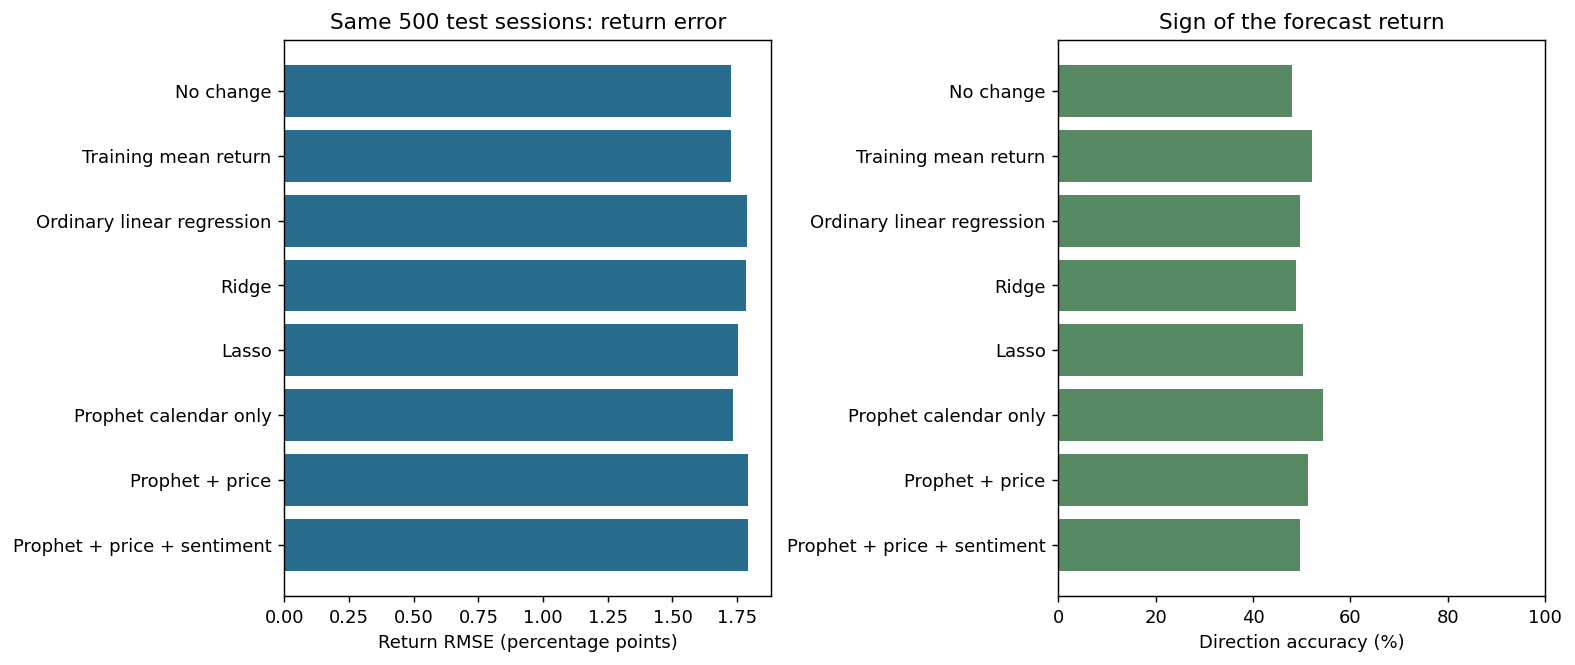

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
axes[0].barh(regression_results.model, regression_results.rmse_pp, color='#286c8e')
axes[0].set_xlabel('Return RMSE (percentage points)')
axes[0].set_title('Same 500 test sessions: return error')
axes[1].barh(regression_results.model, regression_results.direction_accuracy * 100, color='#578a64')
axes[1].set_xlabel('Direction accuracy (%)')
axes[1].set_xlim(0, 100)
axes[1].set_title('Sign of the forecast return')
for ax in axes:
    ax.invert_yaxis()
fig.savefig(OUT / 'prophet_regression_comparison.png', dpi=160)
plt.show()


## AI assistance disclosure

ChatGPT helped locate existing datasets and generate and execute this preliminary notebook.
The team still needs to review the code, source assumptions, and results before submission.


## Observed results from this run

1,787 feature/target examples were created; two split-boundary rows were removed. Training used 1,034 examples, validation 251, and testing 500.

Prophet with calendar trend/seasonality and no extra regressors achieved 54.4% direction accuracy, versus 52.0% for always-up. Its return RMSE was 1.7322 percentage points versus 1.7254 for no change, so the directional difference is not an unqualified forecasting improvement. Prophet with price regressors achieved 51.2%; adding sentiment gave 49.6%. Lasso retained 3 of 17 standardized feature coefficients. All comparison results are retained above and in CSVs. No statistical-significance claim is made.

The added relative-price-to-five-day-mean feature aligns the experiment with the report draft; this rerun supersedes earlier classifier numbers. Classification accuracy for price/sentiment/both was 52.6%/50.8%/52.0% for logistic regression and 51.4%/51.4%/52.8% for random forests.
